In [1]:
# CELL 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files
uploaded = files.upload()

import pandas as pd

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Saving used_cars.csv to used_cars.csv
Dataset loaded successfully!
Shape: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [4]:
# CELL 3: Dataset Exploration

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (4009, 12)

Column Names:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB

Statistical Summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
count,4009,4009,4009.000000,4009,3839,4009,4009,4009,4009,3896,3413,4009
unique,57,1898,NaN,2818,7,1146,62,319,156,2,1,1569
top,Ford,M3 Base,NaN,"110,000 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes,"$15,000"
freq,386,30,NaN,16,3309,52,1037,905,2025,2910,3413,39
mean,NaN,NaN,2015.515590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,6.104816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1974.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

Duplicate Records: 0


In [5]:
# CELL 4: Data Cleaning

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Display cleaned dataset
print("Data cleaning completed!")
print("Remaining rows:", df.shape[0])
print("Remaining columns:", df.shape[1])

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

display(df.head())

Data cleaning completed!
Remaining rows: 3269
Remaining columns: 12

Missing Values:
0

Duplicate Records:
0


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
6,Audi,S3 2.0T Premium Plus,2017,"84,000 mi.",Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes,"$31,000"
7,BMW,740 iL,2001,"242,000 mi.",Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes,"$7,300"


In [6]:
# CELL 5: Identify Target Variable

print("Available columns:")
print(df.columns.tolist())

Available columns:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']


In [7]:
# CELL 6: Select Features and Target

# Automatically detect resale price column
possible_targets = ['selling_price', 'Selling_Price', 'price', 'Price']

target_col = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target_col is None:
    print("Target column not detected!")
    print("Available columns:", df.columns.tolist())
else:
    print("Target column:", target_col)

    # Separate input and output
    X = df.drop(columns=[target_col])
    y = df[target_col]

    print("\nInput features shape:", X.shape)
    print("Target shape:", y.shape)

    display(X.head())
    display(y.head())

Target column: price

Input features shape: (3269, 11)
Target shape: (3269,)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes
6,Audi,S3 2.0T Premium Plus,2017,"84,000 mi.",Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes
7,BMW,740 iL,2001,"242,000 mi.",Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes


,price
0,"$10,300"
1,"$38,005"
3,"$15,500"
6,"$31,000"
7,"$7,300"


In [8]:
# CELL 7: Identify Numerical and Categorical Columns

# Identify column types
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("\nNumerical Columns:", numerical_cols)

print("\nEncoding preparation completed!")

Categorical Columns: ['brand', 'model', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

Numerical Columns: ['model_year']

Encoding preparation completed!


In [9]:
# CELL 8: Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# CELL 9: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Train-Test split completed!")

Training data: (2615, 11)
Testing data: (654, 11)
Train-Test split completed!


In [13]:
# FIX: Convert target price into numeric values

y = (
    y.astype(str)
     .str.replace('$', '', regex=False)
     .str.replace(',', '', regex=False)
     .str.replace('₹', '', regex=False)
     .str.strip()
)

y = pd.to_numeric(y, errors='coerce')

# Remove invalid price records
valid = y.notna() & (y > 0)

X = X.loc[valid].copy()
y = y.loc[valid].copy()

# Split data again after cleaning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Price conversion successful!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Price data type:", y.dtype)

Price conversion successful!
Training records: 2615
Testing records: 654
Price data type: int64


In [14]:
# Train CART Regression Model

cart_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

cart_model.fit(X_train, y_train)

print("CART Regression Tree trained successfully!")

CART Regression Tree trained successfully!


In [15]:
# CELL 11: CART Model Evaluation

# Predict resale prices
y_pred_cart = cart_model.predict(X_test)

# Calculate performance metrics
mae = mean_absolute_error(y_test, y_pred_cart)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_cart))
r2 = r2_score(y_test, y_pred_cart)

print("CART REGRESSION PERFORMANCE")
print("--------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")

CART REGRESSION PERFORMANCE
--------------------------------
MAE: 21342.3
RMSE: 119201.2
R2 Score: 0.0297
R2 Percentage: 2.97 %


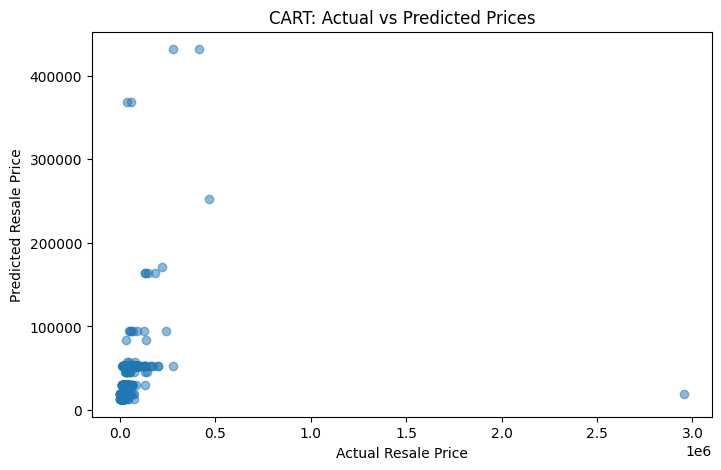

In [16]:
# CELL 12: Actual vs Predicted Graph

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_cart, alpha=0.5)

plt.xlabel("Actual Resale Price")
plt.ylabel("Predicted Resale Price")
plt.title("CART: Actual vs Predicted Prices")

plt.show()

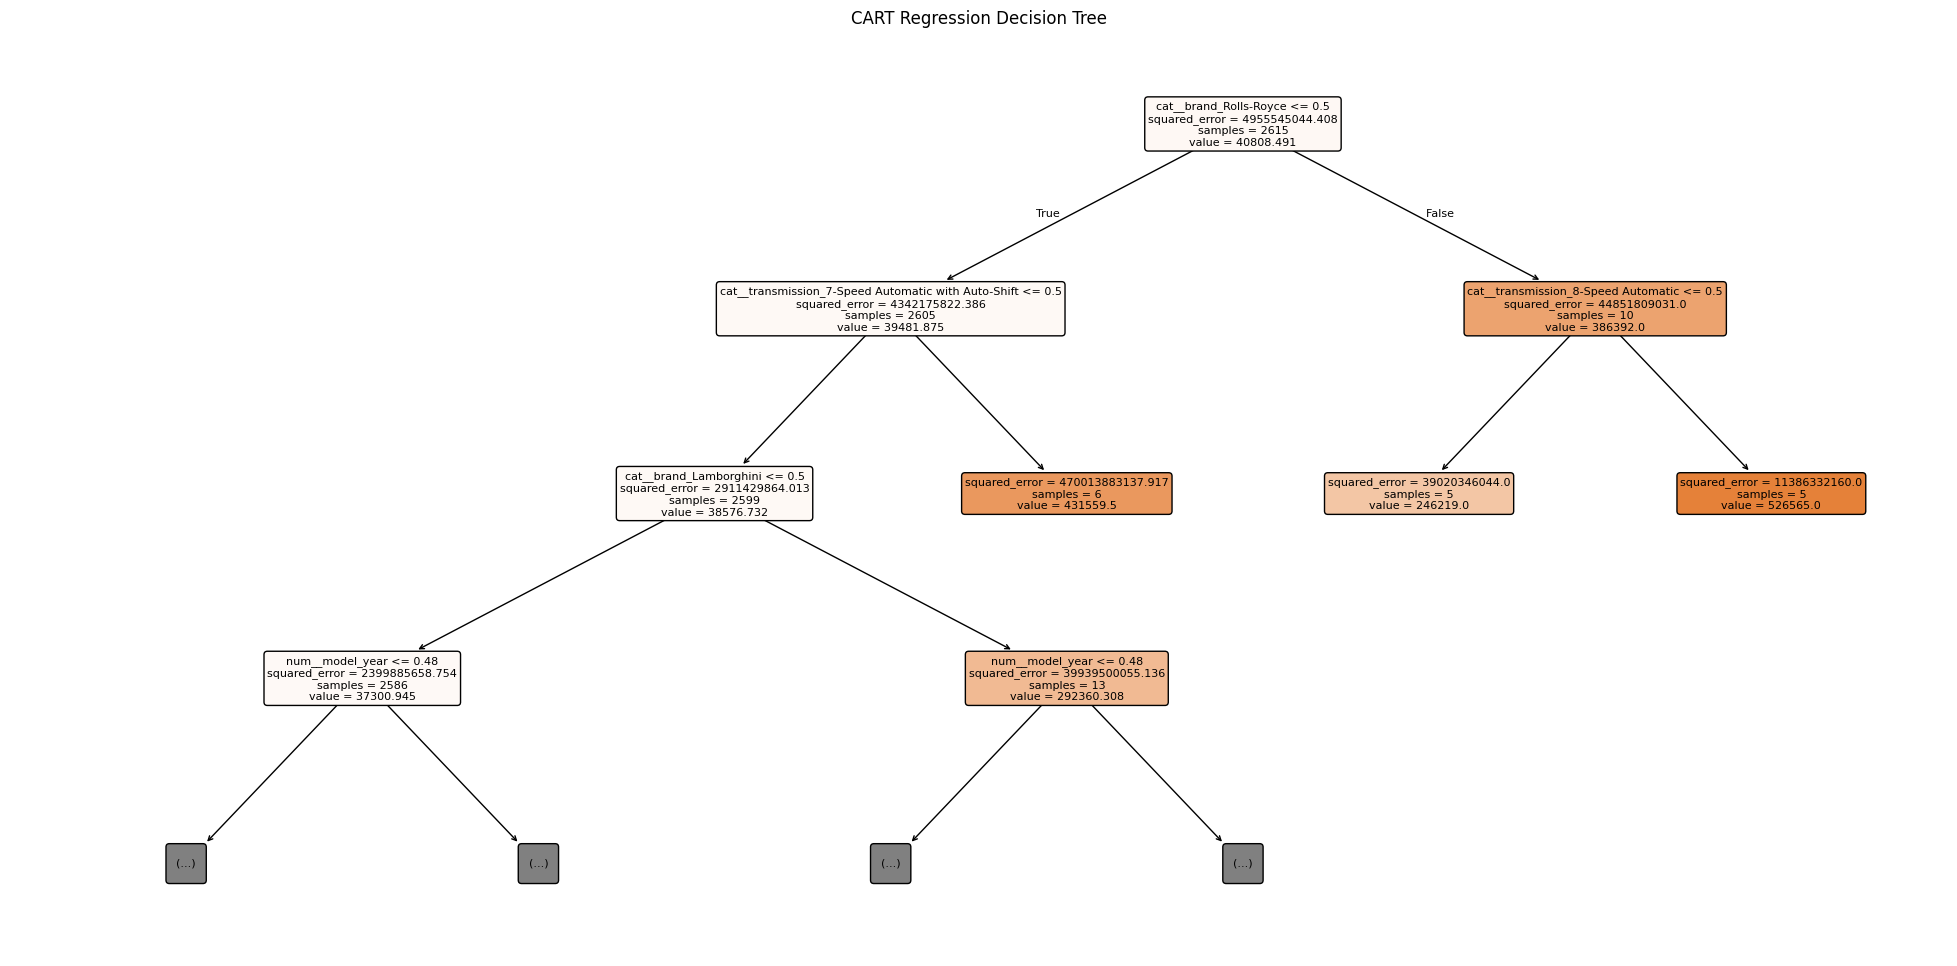

In [17]:
# CELL 13: CART Tree Visualization

# Get trained tree from pipeline
tree_model = cart_model.named_steps['model']

# Get feature names after encoding
feature_names = cart_model.named_steps['preprocessor'].get_feature_names_out()

plt.figure(figsize=(25, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("CART Regression Decision Tree")
plt.show()

In [18]:
# CELL 14: Linear Regression

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [19]:
# CELL 15: Random Forest Regressor

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [20]:
# CELL 16: Gradient Boosting Regressor

gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [21]:
# CELL 17: Model Performance Comparison

models = {
    "CART Regression": y_pred_cart,
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.sort_values(by="R2 Score", ascending=False))

,Algorithm,MAE,RMSE,R2 Score
3,Gradient Boosting,19235.91,118007.85,0.0490
2,Random Forest,20486.23,118727.57,0.0374
1,Linear Regression,28059.22,118747.85,0.0371
0,CART Regression,21342.30,119201.20,0.0297


In [22]:
# CELL 18: Used Car Price Prediction System

# Select the best-performing model based on R2 score
best_model_name = comparison_df.sort_values(
    by="R2 Score", ascending=False
).iloc[0]["Algorithm"]

trained_models = {
    "CART Regression": cart_model,
    "Linear Regression": lr_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)


# Prediction function
def predict_car_resale(car_details):

    input_data = pd.DataFrame([car_details])

    predicted_price = best_model.predict(input_data)[0]

    print("\nEstimated Car Resale Price:")
    print(f"₹ {predicted_price:,.2f}")

    return predicted_price


# Display available input features
print("\nEnter car details using these column names:")
print(X.columns.tolist())

Selected Model: Gradient Boosting

Enter car details using these column names:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']


In [23]:
# CELL 19: Test Price Prediction

# Take one sample car
sample_car = X_test.iloc[0].to_dict()

print("Sample Car Details:")
display(pd.DataFrame([sample_car]))

# Predict resale price
predicted_price = predict_car_resale(sample_car)

Sample Car Details:


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
0,BMW,X5 sDrive35i,2017,"39,250 mi.",Gasoline,300.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,A/T,Black,Beige,None reported,Yes



Estimated Car Resale Price:
₹ 31,737.57


In [24]:
# CELL 20: Cost Complexity Pruning

# Transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Find pruning path
pruning_tree = DecisionTreeRegressor(random_state=42)

path = pruning_tree.cost_complexity_pruning_path(
    X_train_processed, y_train
)

alphas = path.ccp_alphas

# Remove the final alpha that produces a single-node tree
alphas = alphas[:-1]

# Train and evaluate trees with different alpha values
pruning_results = []

for alpha in alphas[::max(1, len(alphas)//20)]:

    tree = DecisionTreeRegressor(
        ccp_alpha=alpha,
        random_state=42
    )

    tree.fit(X_train_processed, y_train)

    X_test_processed = preprocessor.transform(X_test)
    predictions = tree.predict(X_test_processed)

    pruning_results.append({
        "Alpha": alpha,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

pruning_df = pd.DataFrame(pruning_results)

display(pruning_df.sort_values("RMSE").head(10))

,Alpha,MAE,RMSE,R2
12,12544.933078,16266.493684,117653.138794,0.054735
13,18247.919190,16242.776590,117654.602271,0.054712
10,5739.968133,16308.297271,117676.061925,0.054367
11,8524.603816,16321.662722,117677.503035,0.054344
8,2476.634990,16374.885025,117678.085301,0.054334
5,573.613767,16405.530236,117679.548860,0.054311
9,3703.403633,16382.095958,117680.302860,0.054299
7,1663.957935,16403.434377,117680.913474,0.054289
4,275.334608,16410.008894,117681.121917,0.054285
6,1015.874761,16416.436721,117681.573824,0.054278


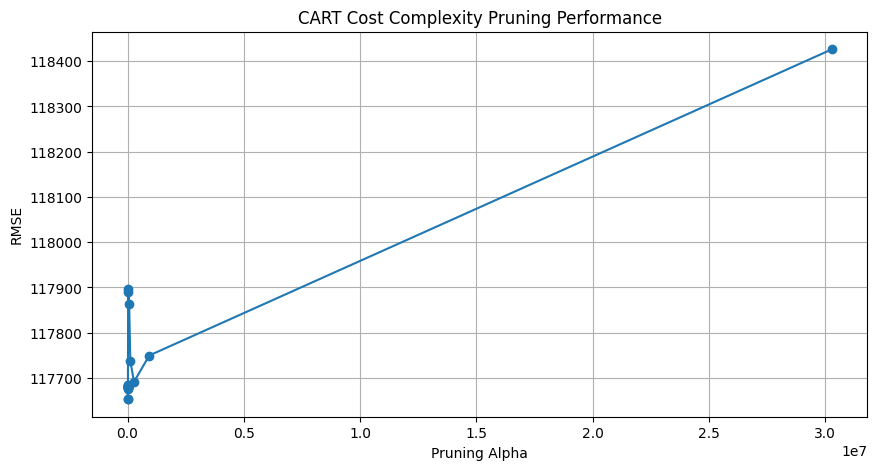

In [25]:
# CELL 21: Pruning Performance Graph

plt.figure(figsize=(10, 5))

plt.plot(pruning_df["Alpha"], pruning_df["RMSE"], marker='o')

plt.xlabel("Pruning Alpha")
plt.ylabel("RMSE")
plt.title("CART Cost Complexity Pruning Performance")
plt.grid(True)

plt.show()

In [26]:
# CELL 22: Best Pruned CART Model

best_alpha = pruning_df.loc[
    pruning_df["RMSE"].idxmin(), "Alpha"
]

final_cart = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        ccp_alpha=best_alpha,
        random_state=42
    ))
])

final_cart.fit(X_train, y_train)

print("Best Pruning Alpha:", best_alpha)
print("Final Pruned CART model trained successfully!")

print("Tree Depth:",
      final_cart.named_steps['model'].get_depth())

print("Number of Leaves:",
      final_cart.named_steps['model'].get_n_leaves())

Best Pruning Alpha: 12544.933078393882
Final Pruned CART model trained successfully!
Tree Depth: 101
Number of Leaves: 1129


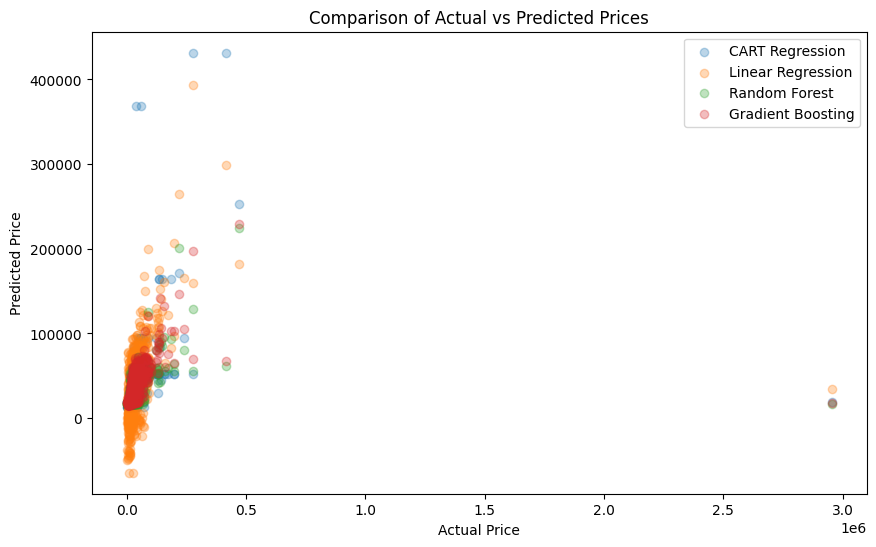

In [27]:
# CELL 23: Model Comparison Graph

plt.figure(figsize=(10, 6))

for name, predictions in models.items():
    plt.scatter(y_test, predictions, alpha=0.3, label=name)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Comparison of Actual vs Predicted Prices")
plt.legend()
plt.show()

In [28]:
# CELL 24: Final Project Summary

print("======================================")
print(" USED CAR RESALE VALUE ESTIMATION")
print("======================================")

display(comparison_df.sort_values("R2 Score", ascending=False))

print("\nBest Model:", best_model_name)
print("Best CART Alpha:", best_alpha)

print("\nPROJECT COMPLETED SUCCESSFULLY!")

 USED CAR RESALE VALUE ESTIMATION


,Algorithm,MAE,RMSE,R2 Score
3,Gradient Boosting,19235.91,118007.85,0.0490
2,Random Forest,20486.23,118727.57,0.0374
1,Linear Regression,28059.22,118747.85,0.0371
0,CART Regression,21342.30,119201.20,0.0297



Best Model: Gradient Boosting
Best CART Alpha: 12544.933078393882

PROJECT COMPLETED SUCCESSFULLY!
